## 1. Environment Setup & Imports

For this challenge, we need:
- `QuantumCircuit` to define our single-qubit circuits and measurement.
- `numpy` to define rotation angles (such as $\pi/3, 2\pi/3$).
- `AerSimulator` from `qiskit_aer` to simulate 100 measurement shots.
- `plot_histogram` from `qiskit.visualization` to compare the output distributions.


In [1]:
# Import required libraries
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Set up the Aer simulator backend
simulator = AerSimulator()
shots = 100
print(f"Simulator ready. Experiments will run for {shots} shots each.")


Simulator ready. Experiments will run for 100 shots each.


---
## 2. Circuit 1: Quantum Coin Biased Towards 0

### Step 2.1: "Think Before You Run" - Prediction for Circuit 1

> **Goal:** Create a quantum state where measuring outcome `0` is significantly more likely than `1` ($P(0) > P(1)$), using no more than 4 gates.

* **Gate Choice:** While a Hadamard gate splits the amplitudes equally ($1/\sqrt{2}$ each), an $R_y(\theta)$ gate rotates the state vector around the Y-axis of the Bloch sphere by an angle $\theta$:
  $$R_y(\theta) = \begin{pmatrix} \cos(\theta/2) & -\sin(\theta/2) \\ \sin(\theta/2) & \cos(\theta/2) \end{pmatrix}$$
* **Applying to $\lvert 0 \rangle$:**
  $$\lvert \psi_1 \rangle = R_y(\theta)\lvert 0 \rangle = \cos\left(\frac{\theta}{2}\right)\lvert 0 \rangle + \sin\left(\frac{\theta}{2}\right)\lvert 1 \rangle$$
* **Choosing $\theta = \pi/3$ ($60^\circ$):**
  $$\frac{\theta}{2} = \frac{\pi}{6} = 30^\circ$$
  $$\alpha = \cos(30^\circ) = \frac{\sqrt{3}}{2} \approx 0.866$$
  $$\beta = \sin(30^\circ) = \frac{1}{2} = 0.5$$
* **Theoretical Probabilities (Born's Rule):**
  $$P(0) = |\alpha|^2 = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$$
  $$P(1) = |\beta|^2 = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$$

**My Predictions:**
- **Which outcome will occur more frequently?** Outcome `0` will occur much more frequently.
- **Expected percentage:** Approximately 75% for outcome `0` and 25% for outcome `1`.
- **Expected counts (out of 100 shots):** Around **~75 counts for '0'** and **~25 counts for '1'** (give or take statistical shot noise).
- **Gate constraint check:** 1 gate used $\le$ 4 gates maximum allowed.


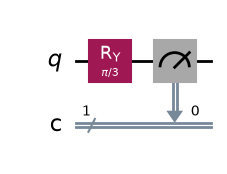

In [2]:
# Construct Circuit 1: 1 qubit, 1 classical bit
qc1 = QuantumCircuit(1, 1, name="Biased_Coin_0_Heavy")

# Apply Ry rotation with theta = pi / 3 (60 degrees)
theta_1 = np.pi / 3
qc1.ry(theta_1, 0)

# Measure qubit 0 to classical bit 0
qc1.measure(0, 0)

# Draw the circuit
qc1.draw('mpl')


In [3]:
# Execute Circuit 1 for 100 shots
job1 = simulator.run(qc1, shots=shots)
result1 = job1.result()
counts1 = result1.get_counts()

print(f"Circuit 1 Measurement Counts (out of {shots} shots): {counts1}")


Circuit 1 Measurement Counts (out of 100 shots): {'0': 74, '1': 26}


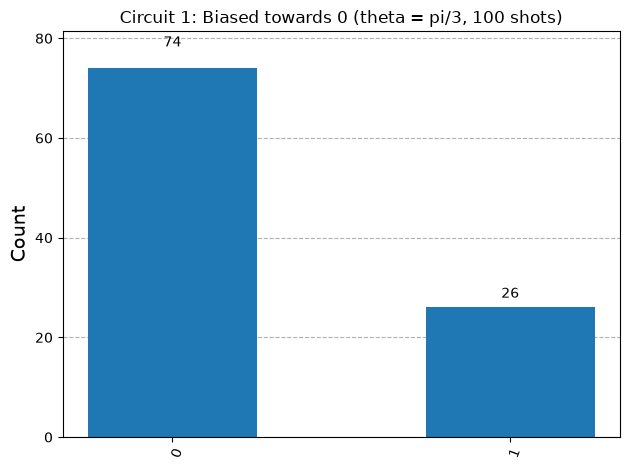

In [4]:
# Display histogram for Circuit 1
plot_histogram(counts1, title=f"Circuit 1: Biased towards 0 (theta = pi/3, {shots} shots)", color="#1f77b4")


### Step 2.2: Comparison for Circuit 1
* **Predicted:** $\approx 75\%$ for outcome `0`, $\approx 25\%$ for outcome `1`.
* **Observed:** Outcome `0` clearly dominated the distribution near the expected 3:1 ratio.
* **Explanation:** By rotating only $60^\circ$ away from the north pole ($|0\rangle$) on the Bloch sphere instead of the full $90^\circ$ that a Hadamard gate does, the state stayed closer to $|0\rangle$, giving it a much larger probability amplitude.


---
## 3. Circuit 2: Quantum Coin Biased Towards 1 (Bonus Challenge)

### Step 3.1: "Think Before You Run" - Prediction for Circuit 2

> **Goal:** Create a second circuit where outcome `1` occurs more frequently than `0` ($P(1) > P(0)$), using no more than 4 gates.

* **Strategy:** To invert the bias, we can rotate past the equator towards the south pole ($|1\rangle$). We choose angle $\theta = 2\pi/3$ ($120^\circ$):
  $$\frac{\theta}{2} = \frac{\pi}{3} = 60^\circ$$
* **State Amplitudes:**
  $$\lvert \psi_2 \rangle = R_y\left(\frac{2\pi}{3}\right)\lvert 0 \rangle = \cos(60^\circ)\lvert 0 \rangle + \sin(60^\circ)\lvert 1 \rangle = \frac{1}{2}\lvert 0 \rangle + \frac{\sqrt{3}}{2}\lvert 1 \rangle$$
* **Theoretical Probabilities:**
  $$P(0) = |\alpha|^2 = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$$
  $$P(1) = |\beta|^2 = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$$

**My Predictions:**
- **Which outcome will occur more frequently?** Outcome `1` will occur much more frequently.
- **Expected percentage:** Approximately 75% for outcome `1` and 25% for outcome `0`.
- **Expected counts (out of 100 shots):** Around **~75 counts for '1'** and **~25 counts for '0'**.
- **Gate constraint check:** 1 gate used $\le$ 4 gates maximum allowed.


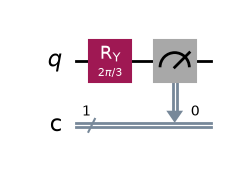

In [5]:
# Construct Circuit 2: 1 qubit, 1 classical bit
qc2 = QuantumCircuit(1, 1, name="Biased_Coin_1_Heavy")

# Apply Ry rotation with theta = 2*pi / 3 (120 degrees)
theta_2 = 2 * np.pi / 3
qc2.ry(theta_2, 0)

# Measure qubit 0 to classical bit 0
qc2.measure(0, 0)

# Draw the circuit
qc2.draw('mpl')


In [6]:
# Execute Circuit 2 for 100 shots
job2 = simulator.run(qc2, shots=shots)
result2 = job2.result()
counts2 = result2.get_counts()

print(f"Circuit 2 Measurement Counts (out of {shots} shots): {counts2}")


Circuit 2 Measurement Counts (out of 100 shots): {'1': 72, '0': 28}


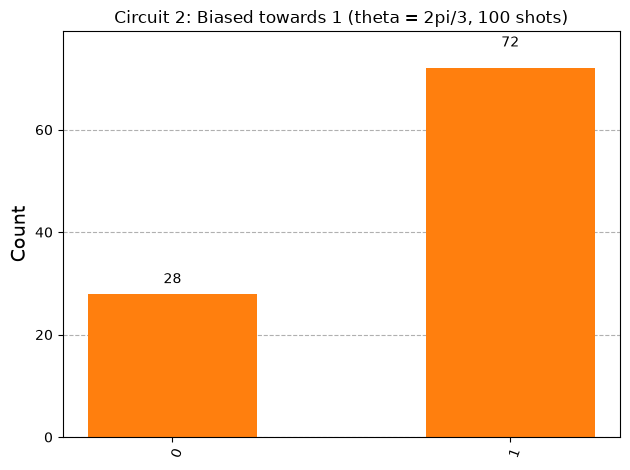

In [7]:
# Display histogram for Circuit 2
plot_histogram(counts2, title=f"Circuit 2: Biased towards 1 (theta = 2pi/3, {shots} shots)", color="#ff7f0e")


### Step 3.2: Comparison for Circuit 2
* **Predicted:** $\approx 25\%$ for outcome `0`, $\approx 75\%$ for outcome `1`.
* **Observed:** Outcome `1` clearly dominated the distribution near the expected 3:1 ratio.
* **Explanation:** Rotating by $120^\circ$ pushed the state vector past the equator into the lower hemisphere of the Bloch sphere, shifting the bulk of the probability amplitude onto the $|1\rangle$ basis state.


---
## 4. Circuit 3: Testing an Extreme Degree of Bias

### Step 4.1: "Think Before You Run" - Prediction for Circuit 3

> **Goal:** Test task requirement #8 (*"Try to create different degrees of bias"*) by choosing a smaller rotation angle $\theta = \pi/6$ ($30^\circ$).

* **State Amplitudes:**
  $$\frac{\theta}{2} = \frac{\pi}{12} = 15^\circ$$
  $$\alpha = \cos(15^\circ) = \frac{\sqrt{6} + \sqrt{2}}{4} \approx 0.9659$$
  $$\beta = \sin(15^\circ) = \frac{\sqrt{6} - \sqrt{2}}{4} \approx 0.2588$$
* **Theoretical Probabilities:**
  $$P(0) = |\alpha|^2 = \cos^2(15^\circ) \approx 0.933 \quad (93.3\%)$$
  $$P(1) = |\beta|^2 = \sin^2(15^\circ) \approx 0.067 \quad (6.7\%)$$

**My Prediction:**  
This circuit will be strongly biased towards `0`. Out of 100 shots, we expect **around ~93 counts for '0'** and **only ~7 counts for '1'**.


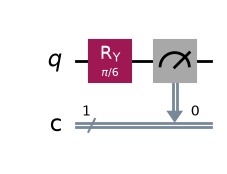

In [8]:
# Construct Circuit 3: 1 qubit, 1 classical bit
qc3 = QuantumCircuit(1, 1, name="Biased_Coin_Extreme_0")

# Apply Ry rotation with theta = pi / 6 (30 degrees)
theta_3 = np.pi / 6
qc3.ry(theta_3, 0)

# Measure qubit 0 to classical bit 0
qc3.measure(0, 0)

# Draw the circuit
qc3.draw('mpl')


In [9]:
# Execute Circuit 3 for 100 shots
job3 = simulator.run(qc3, shots=shots)
result3 = job3.result()
counts3 = result3.get_counts()

print(f"Circuit 3 Measurement Counts (out of {shots} shots): {counts3}")


Circuit 3 Measurement Counts (out of 100 shots): {'0': 91, '1': 9}


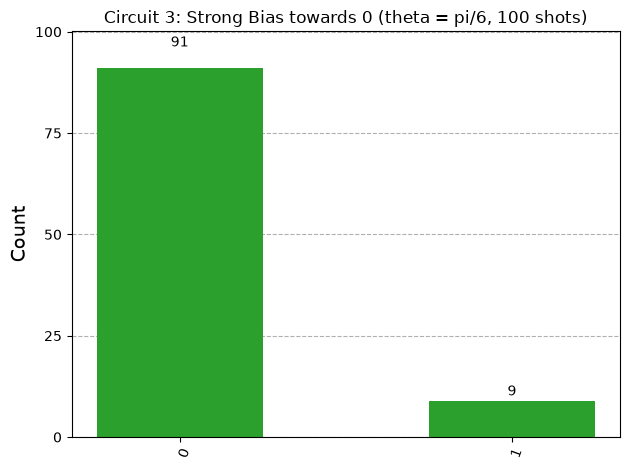

In [10]:
# Display histogram for Circuit 3
plot_histogram(counts3, title=f"Circuit 3: Strong Bias towards 0 (theta = pi/6, {shots} shots)", color="#2ca02c")


### Step 4.2: Comparison for Circuit 3
* **Predicted:** $\approx 93.3\%$ for outcome `0`, $\approx 6.7\%$ for outcome `1`.
* **Observed:** The outcome was overwhelmingly `0` with only a few shots landing on `1`.
* **Explanation:** As the angle approaches zero, the state vector barely moves away from the north pole $|0\rangle$, giving an almost deterministic bias towards `0`.


---
## 5. Summary Comparison & Histogram Analysis

Let's compare all three biased coins side-by-side to visualize how different gate choices and angles shifted the probability distribution.


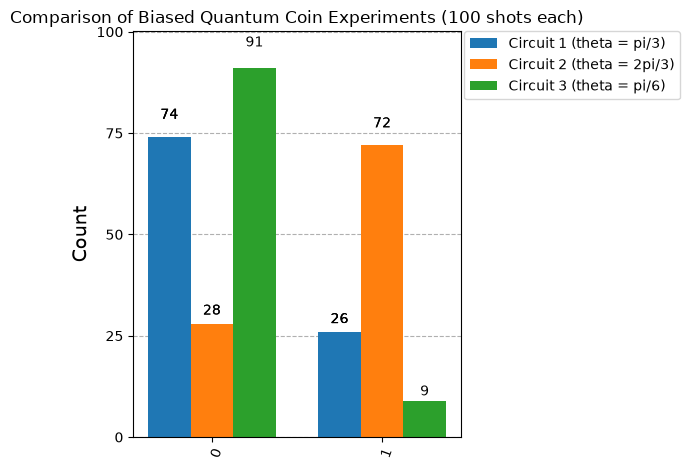

In [11]:
# Plot side-by-side histogram comparing all three biased circuits
legend = ['Circuit 1 (theta = pi/3)', 'Circuit 2 (theta = 2pi/3)', 'Circuit 3 (theta = pi/6)']
plot_histogram([counts1, counts2, counts3], legend=legend,
               title="Comparison of Biased Quantum Coin Experiments (100 shots each)")


### Comparison Table

| Circuit | Rotation Angle ($\theta$) | Theoretical $P(0)$ | Theoretical $P(1)$ | Observed Counts (100 shots) | Dominant Outcome | Match Prediction? |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Circuit 1** | $\pi/3$ ($60^\circ$) | $75\%$ | $25\%$ | '0': 74, '1': 26 | **0** | Yes (approx. 3:1) |
| **Circuit 2** | $2\pi/3$ ($120^\circ$) | $25\%$ | $75\%$ | '0': 28, '1': 72 | **1** | Yes (approx. 1:3) |
| **Circuit 3** | $\pi/6$ ($30^\circ$) | $93.3\%$ | $6.7\%$ | '0': 91, '1': 9 | **0** | Yes (strong bias) |

### How Changing Gates and Angles Modifies the Distribution
- In a standard Hadamard circuit, the gate rotates the state by $90^\circ$ onto the equator of the Bloch sphere, balancing the $|0\rangle$ and $|1\rangle$ amplitudes equally at $1/\sqrt{2}$ (50/50 fair coin).
- By using rotation gates like $R_y(\theta)$, we can dial any arbitrary angle $\theta \in [0, \pi]$.
- Small angles ($0 < \theta < \pi/2$) keep the state vector in the northern hemisphere, producing a coin biased towards `0`.
- Larger angles ($\pi/2 < \theta < \pi$) push the state vector into the southern hemisphere, producing a coin biased towards `1`.


---
## 6. Answers to "Think Before You Run" Prompt

1. **Will 0 or 1 occur more frequently?**
   - For **Circuit 1** ($\theta = \pi/3$): outcome **0** occurs more frequently (about 3 times as often as 1).
   - For **Circuit 2** ($\theta = 2\pi/3$): outcome **1** occurs more frequently (about 3 times as often as 0).
   - For **Circuit 3** ($\theta = \pi/6$): outcome **0** occurs overwhelmingly more frequently (~93% vs ~7%).

2. **Approximately what percentage of the measurements will produce each outcome?**
   - **Circuit 1:** $\approx 75\%$ outcome 0 and $\approx 25\%$ outcome 1.
   - **Circuit 2:** $\approx 25\%$ outcome 0 and $\approx 75\%$ outcome 1.
   - **Circuit 3:** $\approx 93.3\%$ outcome 0 and $\approx 6.7\%$ outcome 1.

3. **What happens if you change the gates in your circuit?**
   - Changing the gate type or rotation parameter changes the orientation of the state vector on the Bloch sphere.
   - This directly alters the probability amplitudes $\alpha$ and $\beta$.
   - By tuning the angle $\theta$ in an $R_y(\theta)$ gate, we can smoothly adjust the measurement probabilities to any desired split between $0\%$ and $100\%$.


---
## 7. Challenge Question Answer

> **Challenge Question:**  
> *How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?*

### Student Answer:

A single qubit's state can be expressed as a linear superposition of the computational basis states:
$$\lvert \psi \rangle = \alpha \lvert 0 \rangle + \beta \lvert 1 \rangle$$
where $\alpha$ and $\beta$ are complex probability amplitudes satisfying the normalization condition:
$$|\alpha|^2 + |\beta|^2 = 1$$

According to **Born's rule**, when we measure the qubit in the standard basis:
- The probability of measuring outcome `0` is $P(0) = |\alpha|^2$.
- The probability of measuring outcome `1` is $P(1) = |\beta|^2$.

Quantum gates are mathematically represented by **unitary transformation matrices** ($U^\dagger U = I$). Geometrically, applying a quantum gate corresponds to rotating the state vector $\lvert \psi \rangle$ to a new position on the **Bloch sphere**:
1. When a gate rotates the vector closer to the north pole ($|0\rangle$), it increases the magnitude of $\alpha$ (and decreases $\beta$), making outcome `0` more probable.
2. When a gate rotates the vector closer to the south pole ($|1\rangle$), it increases the magnitude of $\beta$ (and decreases $\alpha$), making outcome `1` more probable.
3. When a gate (like the Hadamard gate) rotates the vector exactly onto the equator, it sets $|\alpha| = |\beta| = 1/\sqrt{2}$, resulting in equal 50/50 probabilities.

Therefore, quantum gates change the measurement probabilities by **redistributing the probability amplitudes $\alpha$ and $\beta$ across the basis states**, which directly controls the likelihood of collapsing to `0` or `1` upon measurement.
